<a href="https://colab.research.google.com/github/MarokoVo/Data-analytics/blob/main/lab4/lab-4Model%20Evaluation%20and%20Refinement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import cross_val_score, GridSearchCV, train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score

df = pd.read_csv("auto_cleaned.csv")

features = ["horsepower", "curb-weight", "engine-size", "highway-mpg", "normalized-losses", "symboling"]
x_train, x_test, y_train, y_test = train_test_split(df[features], df["price"], test_size=0.2, random_state=42)

Rcross = cross_val_score(LinearRegression(), df[["horsepower"]], df["price"], cv=4)
print("R² по 4 частинах:", Rcross)
print("Середнє:", Rcross.mean(), " Розкид (std):", Rcross.std())

R² по 4 частинах: [0.68660246 0.49763681 0.28254947 0.29055767]
Середнє: 0.43933660206330183  Розкид (std): 0.16677581990381668


Завдання 1. Overfitting

R² навчання: 1.0
R² тест: -19511333.098132614


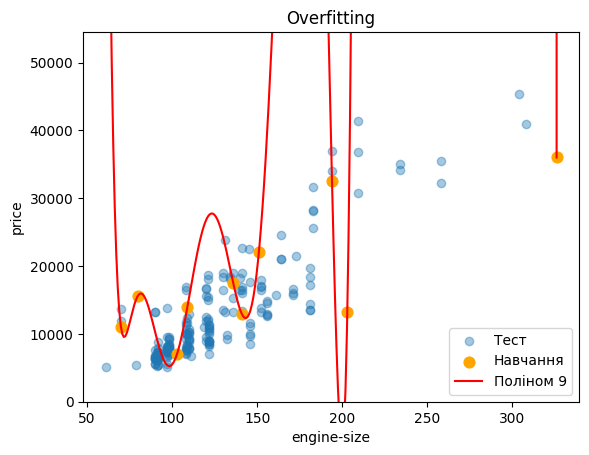

In [10]:
train_small = df.drop_duplicates("engine-size").sample(10, random_state=1)
test_rest = df.drop(train_small.index)

model_over = Polynomial.fit(train_small["engine-size"], train_small["price"], deg=9)

print("R² навчання:", r2_score(train_small["price"], model_over(train_small["engine-size"])))
print("R² тест:", r2_score(test_rest["price"], model_over(test_rest["engine-size"])))

x_line = np.linspace(df["engine-size"].min(), df["engine-size"].max(), 300)
plt.scatter(test_rest["engine-size"], test_rest["price"], alpha=0.4, label="Тест")
plt.scatter(train_small["engine-size"], train_small["price"], color="orange", s=60, label="Навчання")
plt.plot(x_line, model_over(x_line), color="red", label="Поліном 9")
plt.ylim(0, df["price"].max() * 1.2)
plt.xlabel("engine-size"); plt.ylabel("price"); plt.title("Overfitting"); plt.legend(); plt.show()

Завдання 2. Underfitting

R² навчання: 0.0008699679176692454
R² тест: 0.011053700420920354


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


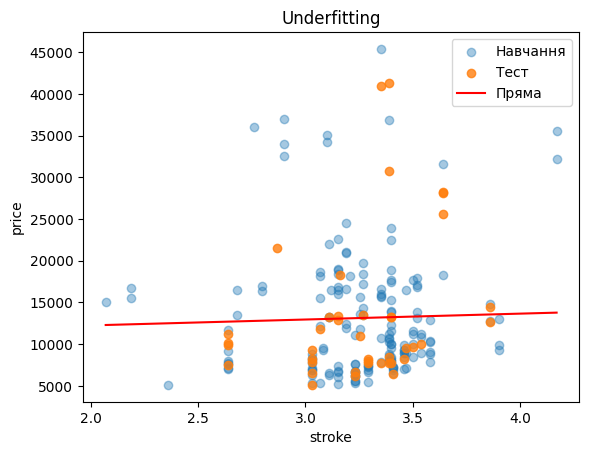

In [11]:
xs_train = df.loc[x_train.index, ["stroke"]]
xs_test = df.loc[x_test.index, ["stroke"]]

under = LinearRegression()
under.fit(xs_train, y_train)

print("R² навчання:", under.score(xs_train, y_train))
print("R² тест:", under.score(xs_test, y_test))

plt.scatter(xs_train, y_train, alpha=0.4, label="Навчання")
plt.scatter(xs_test, y_test, alpha=0.8, label="Тест")
xl = np.linspace(df["stroke"].min(), df["stroke"].max(), 100).reshape(-1, 1)
plt.plot(xl, under.predict(xl), color="red", label="Пряма")
plt.xlabel("stroke"); plt.ylabel("price"); plt.title("Underfitting"); plt.legend(); plt.show()

Завдання 3. GridSearch для Ridge Regression

In [12]:
features3 = ["horsepower", "curb-weight", "engine-size", "highway-mpg"]

pr = PolynomialFeatures(degree=2)
x_train_pr = pr.fit_transform(x_train[features3])
x_test_pr = pr.transform(x_test[features3])

RigeModel = Ridge(alpha=1)
parameters1 = {"alpha": [0.001, 0.1, 1, 10, 100, 1000, 10000]}
Grid1 = GridSearchCV(RigeModel, parameters1, cv=4)
Grid1.fit(x_train_pr, y_train)

print("Найкращий alpha:", Grid1.best_params_)
print("Найкращий R² (крос-валідація):", Grid1.best_score_)

best = Grid1.best_estimator_
print("R² навчання:", best.score(x_train_pr, y_train))
print("R² тест:", best.score(x_test_pr, y_test))

pd.DataFrame(Grid1.cv_results_)[["param_alpha", "mean_test_score"]]

Найкращий alpha: {'alpha': 0.001}
Найкращий R² (крос-валідація): 0.7157404521658854
R² навчання: 0.8462226662455059
R² тест: 0.7739396059520617


/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=8.12258e-19): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=8.51708e-19): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.04271e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.0206e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=8.12258e-17): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python

,param_alpha,mean_test_score
0,0.001,0.715740
1,0.100,0.715529
2,1.000,0.714125
3,10.000,0.706741
4,100.000,0.664595
5,1000.000,0.568056
6,10000.000,0.513281
